<a href="https://colab.research.google.com/github/Ayushcodes-hub/BankPulse/blob/main/notebooks/BankPulse.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# CELL 1: INSTALLATION

!pip install -q pandas numpy matplotlib seaborn scikit-learn joblib


In [ ]:

# CELL 2: IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import zipfile
import requests
import io

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

# CELL 3: DOWNLOAD DATASET

url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

response = requests.get(url, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as outer_zip:

    print("Files inside downloaded archive:")
    print(outer_zip.namelist())

    # Extract the inner bank.zip archive
    inner_name = next(
        name for name in outer_zip.namelist()
        if name.endswith("bank.zip")
    )

    inner_bytes = outer_zip.read(inner_name)

    with zipfile.ZipFile(io.BytesIO(inner_bytes)) as inner_zip:

        csv_name = next(
            name for name in inner_zip.namelist()
            if name.endswith("bank-full.csv")
        )

        csv_bytes = inner_zip.read(csv_name)

        df = pd.read_csv(
            io.BytesIO(csv_bytes),
            sep=";"
        )

print("\nDataset downloaded successfully!")
print("Dataset shape:", df.shape)
df.head()


Files inside downloaded archive:
['bank.zip', 'bank-additional.zip']

Dataset downloaded successfully!
Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


y
no     39922
yes     5289
Name: count, dtype: int64

Percentage distribution:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


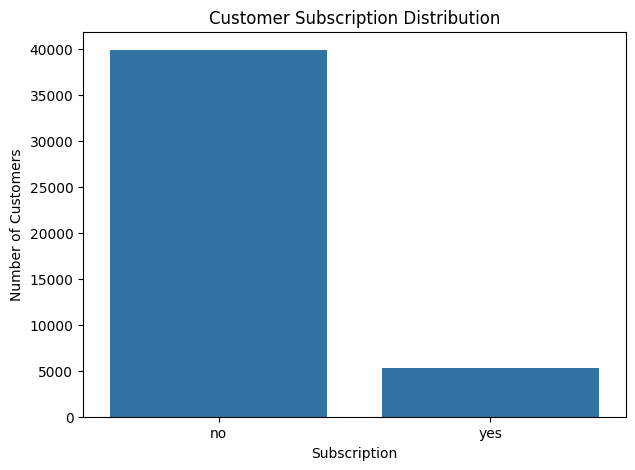

In [ ]:

# CELL 5: TARGET DISTRIBUTION

print(df["y"].value_counts())

print("\nPercentage distribution:")
print(df["y"].value_counts(normalize=True) * 100)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="y"
)

plt.title("Customer Subscription Distribution")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")

plt.show()


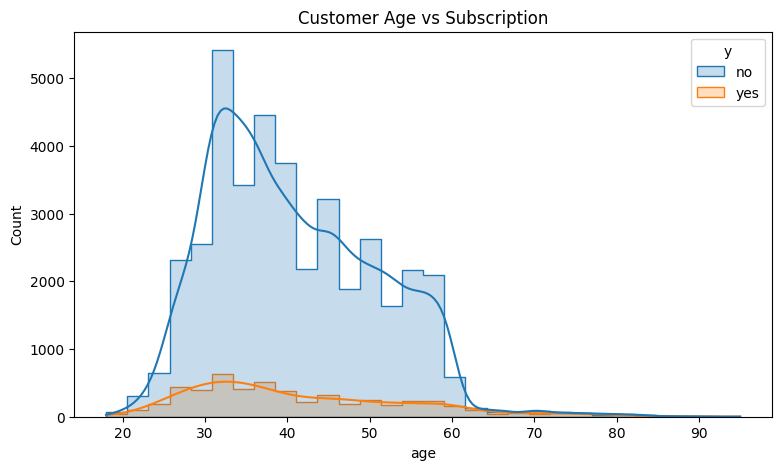

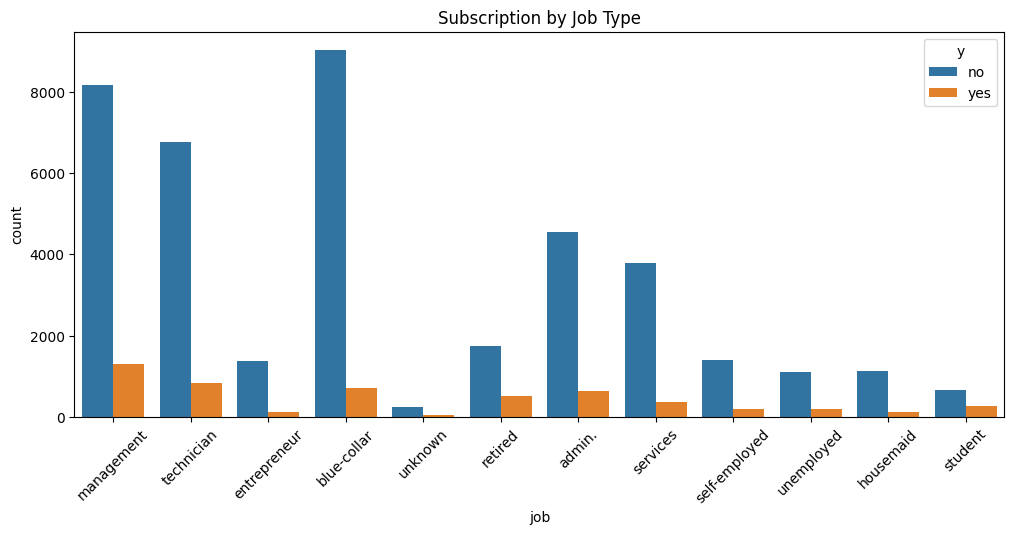

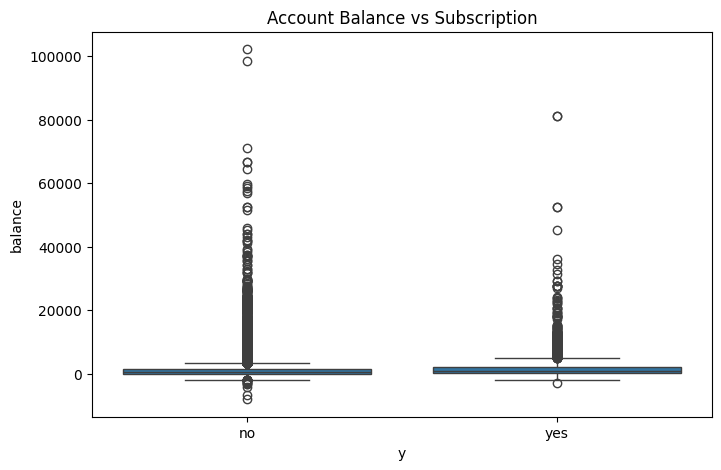

In [ ]:

# CELL 6: VISUAL ANALYSIS

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="age",
    hue="y",
    bins=30,
    kde=True,
    element="step"
)

plt.title("Customer Age vs Subscription")
plt.show()


plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x="job",
    hue="y"
)

plt.xticks(rotation=45)
plt.title("Subscription by Job Type")
plt.show()


plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="y",
    y="balance"
)

plt.title("Account Balance vs Subscription")
plt.show()


In [ ]:

# CELL 7: FEATURE ENGINEERING

data = df.copy()

# Convert target into numerical binary values
data["target"] = data["y"].map({
    "no": 0,
    "yes": 1
})

# Feature indicating whether customer was previously contacted
data["was_previously_contacted"] = (
    data["pdays"] != -1
).astype(int)

# Replace -1 with missing value
# Only meaningful when previous contact exists
data["pdays"] = data["pdays"].replace(-1, np.nan)

# Remove target and leakage-related columns
X = data.drop(
    columns=["y", "target", "duration"]
)

y = data["target"]

print("Features:", X.shape)
print("Target:", y.shape)

print("\nTarget distribution:")
print(y.value_counts(normalize=True))


Features: (45211, 16)
Target: (45211,)

Target distribution:
target
0    0.883015
1    0.116985
Name: proportion, dtype: float64


In [ ]:

# CELL 8: IDENTIFY FEATURE TYPES

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)


Numerical features:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'was_previously_contacted']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [ ]:

# CELL 9: TRAIN / VALIDATION / TEST SPLIT

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))


Training records: 31647
Validation records: 6782
Testing records: 6782

Training target distribution:
target
0    0.883022
1    0.116978
Name: proportion, dtype: float64


In [ ]:

# CELL 10: PREPROCESSING PIPELINE

numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created!")


Preprocessing pipeline created!


In [ ]:

# CELL 11: LOGISTIC REGRESSION

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]
)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

# Predict probabilities on validation data
lr_val_prob = logistic_model.predict_proba(X_val)[:, 1]

print("\nFirst 10 predicted probabilities:")
print(lr_val_prob[:10])


Logistic Regression trained successfully!

First 10 predicted probabilities:
[0.31916854 0.47631967 0.59190791 0.36479249 0.18128071 0.31471772
 0.43909581 0.18510981 0.36176418 0.50202016]


In [ ]:

# CELL 12: RANDOM FOREST

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=15,
            min_samples_split=10,
            min_samples_leaf=4,
            max_features="sqrt",
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]
)

# Train Random Forest
random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

# Predict probabilities
rf_val_prob = random_forest_model.predict_proba(X_val)[:, 1]

print("\nFirst 10 probabilities:")
print(rf_val_prob[:10])


Random Forest trained successfully!

First 10 probabilities:
[0.15932143 0.43989234 0.26501279 0.32675728 0.19420165 0.15924604
 0.43231182 0.2009943  0.32533313 0.47851769]


In [ ]:

# CELL 13: MODEL COMPARISON

def evaluate_model(name, y_true, probabilities, threshold=0.5):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        )
    }


results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_val,
        lr_val_prob
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_val,
        rf_val_prob
    )
)

comparison = pd.DataFrame(results)

display(
    comparison.round(4)
)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7569,0.2693,0.6285,0.3770,0.7720
1,Random Forest,0.8453,0.3913,0.5781,0.4667,0.7989


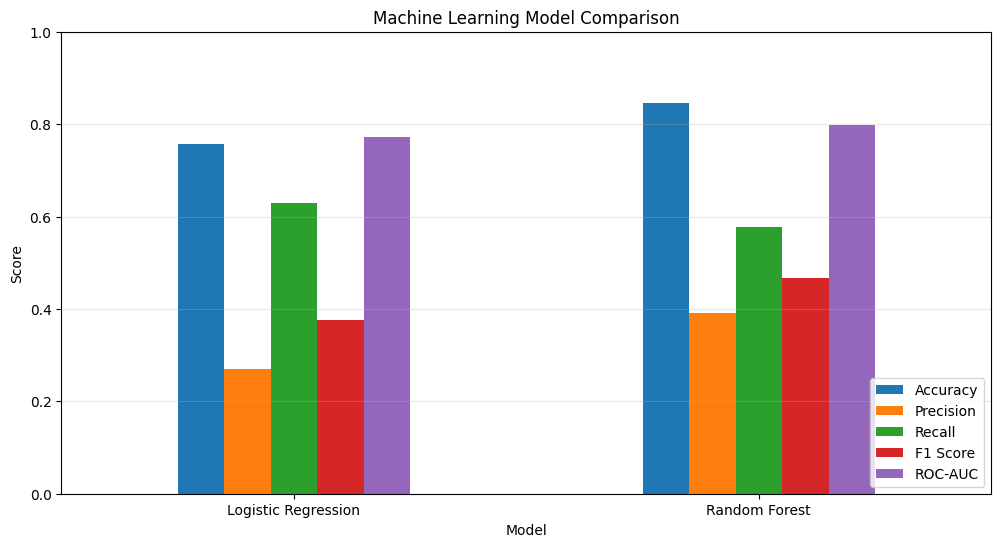

In [ ]:

# CELL 14: PERFORMANCE VISUALIZATION

comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.show()


In [ ]:

# CELL 15: THRESHOLD OPTIMIZATION

thresholds = np.arange(0.10, 0.91, 0.01)

best_threshold = 0.50
best_f1 = 0

# Select Random Forest for threshold optimization
for threshold in thresholds:

    predictions = (
        rf_val_prob >= threshold
    ).astype(int)

    score = f1_score(
        y_val,
        predictions,
        zero_division=0
    )

    if score > best_f1:
        best_f1 = score
        best_threshold = threshold

print("Best threshold:", round(best_threshold, 2))
print("Validation F1-score:", round(best_f1, 4))


Best threshold: 0.54
Validation F1-score: 0.4816


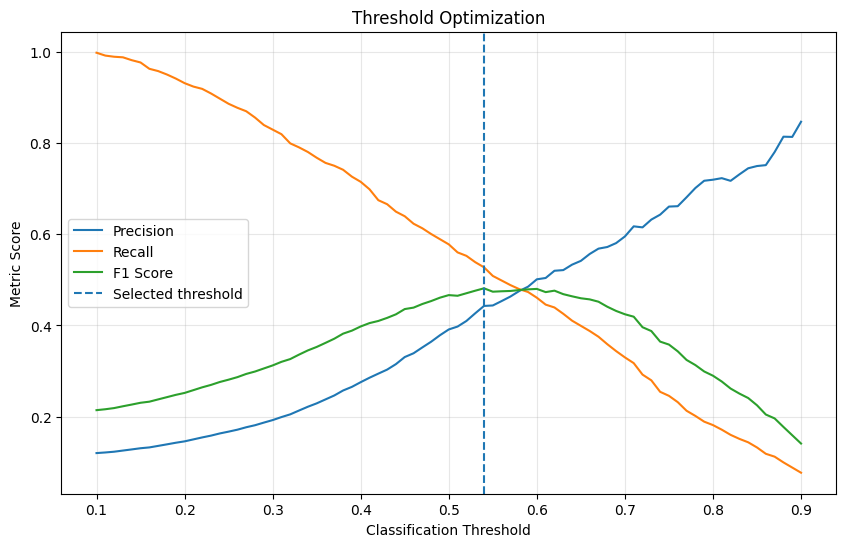

In [ ]:

# CELL 16: THRESHOLD PERFORMANCE

precision_values = []
recall_values = []
f1_values = []

for threshold in thresholds:

    predictions = (
        rf_val_prob >= threshold
    ).astype(int)

    precision_values.append(
        precision_score(
            y_val, predictions, zero_division=0
        )
    )

    recall_values.append(
        recall_score(
            y_val, predictions, zero_division=0
        )
    )

    f1_values.append(
        f1_score(
            y_val, predictions, zero_division=0
        )
    )

plt.figure(figsize=(10, 6))

plt.plot(thresholds, precision_values, label="Precision")
plt.plot(thresholds, recall_values, label="Recall")
plt.plot(thresholds, f1_values, label="F1 Score")

plt.axvline(
    best_threshold,
    linestyle="--",
    label="Selected threshold"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Metric Score")
plt.title("Threshold Optimization")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:

# CELL 17: FINAL TEST EVALUATION

rf_test_prob = random_forest_model.predict_proba(
    X_test
)[:, 1]

rf_test_predictions = (
    rf_test_prob >= best_threshold
).astype(int)

print("FINAL TEST RESULTS")

print("\nAccuracy:",
      accuracy_score(y_test, rf_test_predictions))

print("Precision:",
      precision_score(y_test, rf_test_predictions))

print("Recall:",
      recall_score(y_test, rf_test_predictions))

print("F1 Score:",
      f1_score(y_test, rf_test_predictions))

print("ROC-AUC:",
      roc_auc_score(y_test, rf_test_prob))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        rf_test_predictions,
        target_names=["No Subscription", "Subscription"]
    )
)


FINAL TEST RESULTS

Accuracy: 0.8658212916543793
Precision: 0.4387434554973822
Recall: 0.5283732660781841
F1 Score: 0.4794050343249428
ROC-AUC: 0.7924924151612973

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.94      0.91      0.92      5989
   Subscription       0.44      0.53      0.48       793

       accuracy                           0.87      6782
      macro avg       0.69      0.72      0.70      6782
   weighted avg       0.88      0.87      0.87      6782



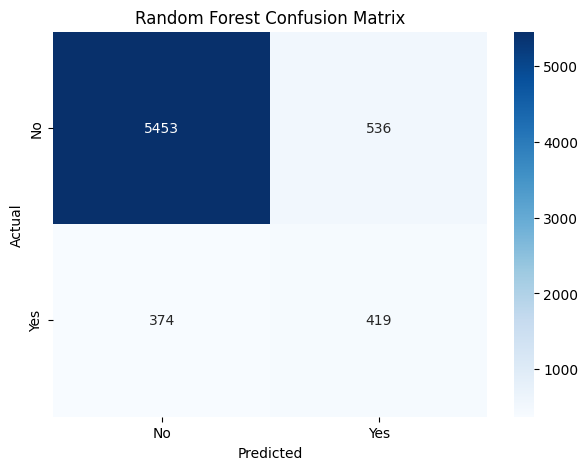

In [ ]:

# CELL 18: CONFUSION MATRIX

cm = confusion_matrix(
    y_test,
    rf_test_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()


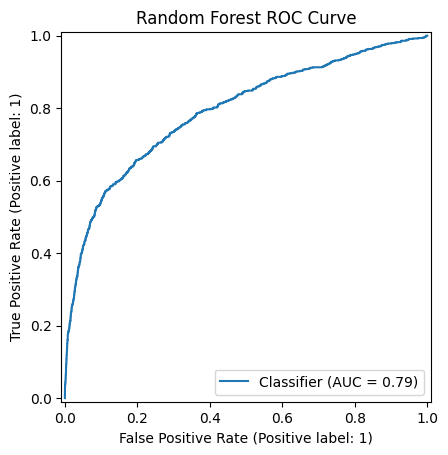

In [ ]:

# CELL 19: ROC CURVE

RocCurveDisplay.from_predictions(
    y_test,
    rf_test_prob
)

plt.title("Random Forest ROC Curve")
plt.show()


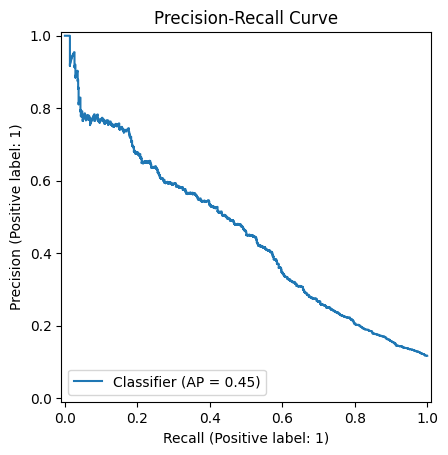

In [ ]:

# CELL 20: PRECISION-RECALL CURVE

PrecisionRecallDisplay.from_predictions(
    y_test,
    rf_test_prob
)

plt.title("Precision-Recall Curve")
plt.show()


,Feature,Importance
10,month,0.099499
8,contact,0.090601
6,housing,0.042045
14,poutcome,0.036532
9,day,0.026501
0,age,0.011648
7,loan,0.010003
15,was_previously_contacted,0.009000
11,campaign,0.008525
5,balance,0.008121


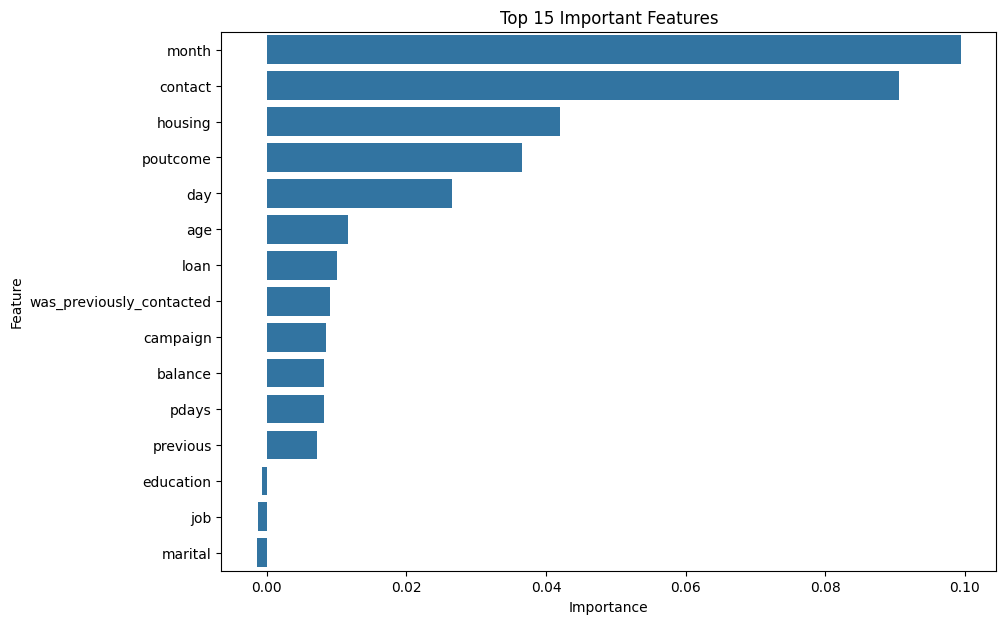

In [ ]:

# CELL 21: PERMUTATION FEATURE IMPORTANCE

importance_result = permutation_importance(
    random_forest_model,
    X_val,
    y_val,
    n_repeats=5,
    random_state=RANDOM_STATE,
    scoring="f1",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": importance_result.importances_mean
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")
plt.show()


In [ ]:

# CELL 22: HYPERPARAMETER TUNING

from sklearn.model_selection import RandomizedSearchCV

parameter_grid = {
    "classifier__n_estimators": [150, 250, 350],
    "classifier__max_depth": [10, 15, 20, None],
    "classifier__min_samples_split": [5, 10, 15],
    "classifier__min_samples_leaf": [2, 4, 6],
    "classifier__max_features": ["sqrt", "log2"],
    "classifier__class_weight": ["balanced", "balanced_subsample"]
}

random_search = RandomizedSearchCV(
    estimator=random_forest_model,
    param_distributions=parameter_grid,
    n_iter=12,
    scoring="f1",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

# Only training data is used here
random_search.fit(X_train, y_train)

print("Best parameters:")
print(random_search.best_params_)

print("\nBest cross-validation F1:")
print(random_search.best_score_)

tuned_model = random_search.best_estimator_


Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters:
{'classifier__n_estimators': 150, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'log2', 'classifier__max_depth': None, 'classifier__class_weight': 'balanced_subsample'}

Best cross-validation F1:
0.4637789926177383


In [ ]:

# CELL 23: EVALUATE TUNED MODEL

tuned_val_prob = tuned_model.predict_proba(X_val)[:, 1]

tuned_thresholds = np.arange(0.10, 0.91, 0.01)

tuned_best_threshold = max(
    tuned_thresholds,
    key=lambda t: f1_score(
        y_val,
        (tuned_val_prob >= t).astype(int),
        zero_division=0
    )
)

tuned_test_prob = tuned_model.predict_proba(X_test)[:, 1]

tuned_test_predictions = (
    tuned_test_prob >= tuned_best_threshold
).astype(int)

print("Selected threshold:", tuned_best_threshold)

print("\nTuned Model Test Results:")

print(classification_report(
    y_test,
    tuned_test_predictions,
    target_names=["No Subscription", "Subscription"]
))

print("ROC-AUC:",
      roc_auc_score(y_test, tuned_test_prob))


Selected threshold: 0.5299999999999998

Tuned Model Test Results:
                 precision    recall  f1-score   support

No Subscription       0.93      0.92      0.93      5989
   Subscription       0.46      0.49      0.47       793

       accuracy                           0.87      6782
      macro avg       0.69      0.71      0.70      6782
   weighted avg       0.88      0.87      0.87      6782

ROC-AUC: 0.7903821992273771


In [ ]:

# CELL 24: SAVE MODEL

os.makedirs("bankpulse_models", exist_ok=True)

model_path = "bankpulse_models/bankpulse_random_forest.pkl"

joblib.dump(
    {
        "model": tuned_model,
        "threshold": tuned_best_threshold,
        "feature_columns": X.columns.tolist()
    },
    model_path
)

print("Model saved successfully!")
print("Saved at:", model_path)


Model saved successfully!
Saved at: bankpulse_models/bankpulse_random_forest.pkl


In [ ]:

# CELL 25: LOAD MODEL

saved_artifact = joblib.load(model_path)

loaded_model = saved_artifact["model"]
loaded_threshold = saved_artifact["threshold"]

print("Model loaded successfully!")
print("Decision threshold:", loaded_threshold)


Model loaded successfully!
Decision threshold: 0.5299999999999998


In [ ]:

# CELL 26: CUSTOMER PREDICTION

new_customer = X_test.iloc[[0]].copy()

probability = loaded_model.predict_proba(
    new_customer
)[0][1]

prediction = int(
    probability >= loaded_threshold
)

print("Customer information:")
display(new_customer)

print("\nSubscription probability:",
      round(probability * 100, 2), "%")

if prediction == 1:
    print("Prediction: LIKELY TO SUBSCRIBE")
else:
    print("Prediction: UNLIKELY TO SUBSCRIBE")


Customer information:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,was_previously_contacted
8984,43,entrepreneur,married,tertiary,yes,-250,no,no,unknown,5,jun,1,NaN,0,unknown,0



Subscription probability: 20.79 %
Prediction: UNLIKELY TO SUBSCRIBE


In [ ]:

# CELL 27: REUSABLE PREDICTION FUNCTION

def predict_customer(customer_data):

    if isinstance(customer_data, dict):
        customer_data = pd.DataFrame([customer_data])

    customer_data = customer_data[
        X.columns
    ]

    probability = loaded_model.predict_proba(
        customer_data
    )[:, 1]

    predictions = (
        probability >= loaded_threshold
    ).astype(int)

    results = pd.DataFrame({
        "Subscription_Probability": probability,
        "Prediction": predictions
    })

    results["Prediction"] = results["Prediction"].map({
        0: "Unlikely",
        1: "Likely"
    })

    return results


# Demonstration
prediction_result = predict_customer(new_customer)

display(prediction_result)


,Subscription_Probability,Prediction
0,0.207866,Unlikely
